# Cell2Cell Customer Churn: EDA, Preprocessing, Models and Final Test Result

**Course:** DATA 4380 group project (UT Arlington) · **Dataset:** Cell2Cell wireless carrier data (51,047 customers, 58 columns, 28.8% churn)

**What this notebook does:** explore the data, clean it, build leakage-safe pipelines, compare baseline models, try class weights, SMOTE, feature engineering, feature selection and a tuned cutoff, then score the test set once.

**How we decide:** all choices use 5-fold stratified cross-validation on the training set. The 20% test set is touched only once, at the end. Main metrics are recall, F1, ROC-AUC and PR-AUC, because accuracy is misleading when only 29% of customers churn.

Run top to bottom. Data download and environment instructions are in the repository README.

---
# Part 1. Explore the data

### Imports and load

In [14]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

pd.set_option("display.max_columns", None)

from pathlib import Path

# Put the CSV in tabular/data/ (see README). The other paths let the notebook run from Colab or the same folder.
DATA_PATH = next(p for p in ["/content/cell2celltrain.csv"] if Path(p).exists())

df = pd.read_csv(DATA_PATH)
print("Shape:", df.shape)
df.head()

Shape: (51047, 58)


,CustomerID,Churn,MonthlyRevenue,MonthlyMinutes,TotalRecurringCharge,DirectorAssistedCalls,OverageMinutes,RoamingCalls,PercChangeMinutes,PercChangeRevenues,DroppedCalls,BlockedCalls,UnansweredCalls,CustomerCareCalls,ThreewayCalls,ReceivedCalls,OutboundCalls,InboundCalls,PeakCallsInOut,OffPeakCallsInOut,DroppedBlockedCalls,CallForwardingCalls,CallWaitingCalls,MonthsInService,UniqueSubs,ActiveSubs,ServiceArea,Handsets,HandsetModels,CurrentEquipmentDays,AgeHH1,AgeHH2,ChildrenInHH,HandsetRefurbished,HandsetWebCapable,TruckOwner,RVOwner,Homeownership,BuysViaMailOrder,RespondsToMailOffers,OptOutMailings,NonUSTravel,OwnsComputer,HasCreditCard,RetentionCalls,RetentionOffersAccepted,NewCellphoneUser,NotNewCellphoneUser,ReferralsMadeBySubscriber,IncomeGroup,OwnsMotorcycle,AdjustmentsToCreditRating,HandsetPrice,MadeCallToRetentionTeam,CreditRating,PrizmCode,Occupation,MaritalStatus
0,3000002,Yes,24.00,219.0,22.0,0.25,0.0,0.0,-157.0,-19.0,0.7,0.7,6.3,0.0,0.0,97.2,0.0,0.0,58.0,24.0,1.3,0.0,0.3,61,2,1,SEAPOR503,2.0,2.0,361.0,62.0,0.0,No,No,Yes,No,No,Known,Yes,Yes,No,No,Yes,Yes,1,0,No,No,0,4,No,0,30,Yes,1-Highest,Suburban,Professional,No
1,3000010,Yes,16.99,10.0,17.0,0.00,0.0,0.0,-4.0,0.0,0.3,0.0,2.7,0.0,0.0,0.0,0.0,0.0,5.0,1.0,0.3,0.0,0.0,58,1,1,PITHOM412,2.0,1.0,1504.0,40.0,42.0,Yes,No,No,No,No,Known,Yes,Yes,No,No,Yes,Yes,0,0,Yes,No,0,5,No,0,30,No,4-Medium,Suburban,Professional,Yes
2,3000014,No,38.00,8.0,38.0,0.00,0.0,0.0,-2.0,0.0,0.0,0.0,0.0,0.0,0.0,0.4,0.3,0.0,1.3,3.7,0.0,0.0,0.0,60,1,1,MILMIL414,1.0,1.0,1812.0,26.0,26.0,Yes,No,No,No,No,Unknown,No,No,No,No,No,Yes,0,0,Yes,No,0,6,No,0,Unknown,No,3-Good,Town,Crafts,Yes
3,3000022,No,82.28,1312.0,75.0,1.24,0.0,0.0,157.0,8.1,52.0,7.7,76.0,4.3,1.3,200.3,370.3,147.0,555.7,303.7,59.7,0.0,22.7,59,2,2,PITHOM412,9.0,4.0,458.0,30.0,0.0,No,No,Yes,No,No,Known,Yes,Yes,No,No,No,Yes,0,0,Yes,No,0,6,No,0,10,No,4-Medium,Other,Other,No
4,3000026,Yes,17.14,0.0,17.0,0.00,0.0,0.0,0.0,-0.2,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,53,2,2,OKCTUL918,4.0,3.0,852.0,46.0,54.0,No,No,No,No,No,Known,Yes,Yes,No,No,Yes,Yes,0,0,No,Yes,0,9,No,1,10,No,1-Highest,Other,Professional,Yes


### Columns and data types

In [15]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 51047 entries, 0 to 51046
Data columns (total 58 columns):
 #   Column                     Non-Null Count  Dtype  
---  ------                     --------------  -----  
 0   CustomerID                 51047 non-null  int64  
 1   Churn                      51047 non-null  object 
 2   MonthlyRevenue             50891 non-null  float64
 3   MonthlyMinutes             50891 non-null  float64
 4   TotalRecurringCharge       50891 non-null  float64
 5   DirectorAssistedCalls      50891 non-null  float64
 6   OverageMinutes             50891 non-null  float64
 7   RoamingCalls               50891 non-null  float64
 8   PercChangeMinutes          50680 non-null  float64
 9   PercChangeRevenues         50680 non-null  float64
 10  DroppedCalls               51047 non-null  float64
 11  BlockedCalls               51047 non-null  float64
 12  UnansweredCalls            51047 non-null  float64
 13  CustomerCareCalls          51047 non-null  flo

### Missing values

In [16]:
missing = df.isnull().sum()
missing[missing > 0].sort_values(ascending=False)

,0
AgeHH2,909
AgeHH1,909
PercChangeRevenues,367
PercChangeMinutes,367
MonthlyRevenue,156
MonthlyMinutes,156
RoamingCalls,156
OverageMinutes,156
DirectorAssistedCalls,156
TotalRecurringCharge,156


### Duplicates and the ID column

In [17]:
print("Exact duplicate rows:", df.duplicated().sum())
print("Duplicates ignoring CustomerID:", df.drop(columns="CustomerID").duplicated().sum())
print("Unique CustomerIDs:", df["CustomerID"].nunique(), "of", len(df))

Exact duplicate rows: 0
Duplicates ignoring CustomerID: 0
Unique CustomerIDs: 51047 of 51047


### The target

In [18]:
print(df["Churn"].value_counts())
print((df["Churn"].value_counts(normalize=True) * 100).round(2))

Churn
No     36336
Yes    14711
Name: count, dtype: int64
Churn
No     71.18
Yes    28.82
Name: proportion, dtype: float64


### Numeric summary

In [19]:
df.describe().T

,count,mean,std,min,25%,50%,75%,max
CustomerID,51047.0,3.201957e+06,116905.561666,3000002.00,3100632.00,3201534.00,3305376.000,3399994.00
MonthlyRevenue,50891.0,5.883449e+01,44.507336,-6.17,33.61,48.46,71.065,1223.38
MonthlyMinutes,50891.0,5.256534e+02,529.871063,0.00,158.00,366.00,723.000,7359.00
TotalRecurringCharge,50891.0,4.683009e+01,23.848871,-11.00,30.00,45.00,60.000,400.00
DirectorAssistedCalls,50891.0,8.952290e-01,2.228546,0.00,0.00,0.25,0.990,159.39
OverageMinutes,50891.0,4.002778e+01,96.588076,0.00,0.00,3.00,41.000,4321.00
RoamingCalls,50891.0,1.236244e+00,9.818294,0.00,0.00,0.00,0.300,1112.40
PercChangeMinutes,50680.0,-1.154791e+01,257.514772,-3875.00,-83.00,-5.00,66.000,5192.00
PercChangeRevenues,50680.0,-1.191985e+00,39.574915,-1107.70,-7.10,-0.30,1.600,2483.50
DroppedCalls,51047.0,6.011489e+00,9.043955,0.00,0.70,3.00,7.700,221.70


### Categorical columns

In [20]:
cat_cols = df.select_dtypes(exclude="number").columns.drop(["Churn", "ServiceArea"])
for col in cat_cols:
    print("\n", df[col].value_counts())

print("\nServiceArea unique values:", df["ServiceArea"].nunique())


 ChildrenInHH
No     38679
Yes    12368
Name: count, dtype: int64

 HandsetRefurbished
No     43956
Yes     7091
Name: count, dtype: int64

 HandsetWebCapable
Yes    46046
No      5001
Name: count, dtype: int64

 TruckOwner
No     41524
Yes     9523
Name: count, dtype: int64

 RVOwner
No     46894
Yes     4153
Name: count, dtype: int64

 Homeownership
Known      33987
Unknown    17060
Name: count, dtype: int64

 BuysViaMailOrder
No     32596
Yes    18451
Name: count, dtype: int64

 RespondsToMailOffers
No     31821
Yes    19226
Name: count, dtype: int64

 OptOutMailings
No     50295
Yes      752
Name: count, dtype: int64

 NonUSTravel
No     48168
Yes     2879
Name: count, dtype: int64

 OwnsComputer
No     41583
Yes     9464
Name: count, dtype: int64

 HasCreditCard
Yes    34503
No     16544
Name: count, dtype: int64

 NewCellphoneUser
No     41223
Yes     9824
Name: count, dtype: int64

 NotNewCellphoneUser
No     44012
Yes     7035
Name: count, dtype: int64

 OwnsMotorcycle
No     

### Hidden “unknown” values

In [21]:
print("AgeHH1 == 0:             ", (df["AgeHH1"] == 0).sum())
print("AgeHH2 == 0:             ", (df["AgeHH2"] == 0).sum())
print("IncomeGroup == 0:        ", (df["IncomeGroup"] == 0).sum())
print("HandsetPrice 'Unknown':  ", (df["HandsetPrice"] == "Unknown").sum())
print("MaritalStatus 'Unknown': ", (df["MaritalStatus"] == "Unknown").sum())
print("Homeownership 'Unknown': ", (df["Homeownership"] == "Unknown").sum())
print("\nNegative MonthlyRevenue:      ", (df["MonthlyRevenue"] < 0).sum())
print("Negative TotalRecurringCharge:", (df["TotalRecurringCharge"] < 0).sum())
print("Negative CurrentEquipmentDays:", (df["CurrentEquipmentDays"] < 0).sum())

AgeHH1 == 0:              13917
AgeHH2 == 0:              26087
IncomeGroup == 0:         12835
HandsetPrice 'Unknown':   28982
MaritalStatus 'Unknown':  19700
Homeownership 'Unknown':  17060

Negative MonthlyRevenue:       3
Negative TotalRecurringCharge: 8
Negative CurrentEquipmentDays: 76


### A first look at churn by group

In [22]:
for col in ["CreditRating", "MadeCallToRetentionTeam", "HandsetWebCapable", "PrizmCode"]:
    print(f"\n{col}")
    print((pd.crosstab(df[col], df["Churn"], normalize="index") * 100).round(1))


CreditRating
Churn           No   Yes
CreditRating            
1-Highest     69.2  30.8
2-High        69.9  30.1
3-Good        69.0  31.0
4-Medium      73.9  26.1
5-Low         77.9  22.1
6-VeryLow     72.6  27.4
7-Lowest      71.1  28.9

MadeCallToRetentionTeam
Churn                      No   Yes
MadeCallToRetentionTeam            
No                       71.8  28.2
Yes                      55.0  45.0

HandsetWebCapable
Churn                No   Yes
HandsetWebCapable            
No                 62.6  37.4
Yes                72.1  27.9

PrizmCode
Churn        No   Yes
PrizmCode            
Other      71.4  28.6
Rural      68.3  31.7
Suburban   71.9  28.1
Town       70.0  30.0


### Which numeric columns move with churn?

In [23]:
y = (df["Churn"] == "Yes").astype(int)
corr = df.select_dtypes("number").drop(columns="CustomerID").corrwith(y).sort_values()
print("Most negative:\n", corr.head(6).round(3))
print("\nMost positive:\n", corr.tail(6).round(3))

Most negative:
 TotalRecurringCharge   -0.061
MonthlyMinutes         -0.050
OffPeakCallsInOut      -0.041
HandsetModels          -0.040
PeakCallsInOut         -0.040
ReceivedCalls          -0.037
dtype: float64

Most positive:
 OverageMinutes             0.016
MonthsInService            0.019
UniqueSubs                 0.035
RetentionOffersAccepted    0.035
RetentionCalls             0.065
CurrentEquipmentDays       0.104
dtype: float64


---
# Part 2. Visualizations (training set only)

### Split first, then plot

In [24]:
# Decision: split FIRST (stratified 80/20) so the 20% test set never influences imputation, scaling, encoding, tuning or the cutoff.
import seaborn as sns
from sklearn.model_selection import train_test_split

BLUE, ORANGE, GREY = "#2a78d6", "#eb6834", "#52514e"

df["Churn"] = (df["Churn"] == "Yes").astype(int)
train_df, test_df = train_test_split(df, test_size=0.2, stratify=df["Churn"], random_state=42)
train_df = train_df.drop(columns="CustomerID")

overall = train_df["Churn"].mean() * 100
print("Train:", train_df.shape, " Test:", test_df.shape)
print("Churn rate in train:", round(overall, 2), "%")

Train: (40837, 57)  Test: (10210, 58)
Churn rate in train: 28.82 %


### Target bar chart

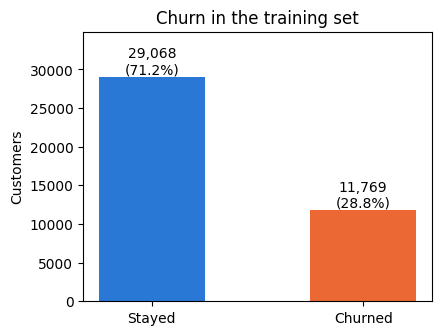

In [25]:
counts = train_df["Churn"].value_counts().sort_index()
fig, ax = plt.subplots(figsize=(4.5, 3.5))
ax.bar(["Stayed", "Churned"], counts.values, color=[BLUE, ORANGE], width=0.5)
for i, v in enumerate(counts.values):
    ax.text(i, v, f"{v:,}\n({v / counts.sum() * 100:.1f}%)", ha="center", va="bottom")
ax.set_ylim(0, counts.max() * 1.2)
ax.set_title("Churn in the training set")
ax.set_ylabel("Customers")
plt.show()

### Missing values: real blanks and hidden “unknowns”

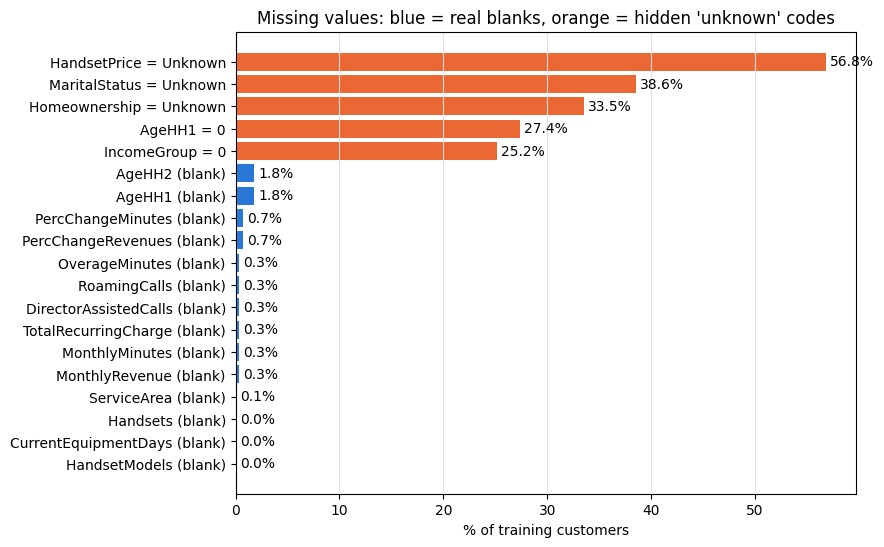

In [26]:
unknown = pd.Series({
    "AgeHH1 = 0": (train_df["AgeHH1"] == 0).sum(),
    "IncomeGroup = 0": (train_df["IncomeGroup"] == 0).sum(),
    "HandsetPrice = Unknown": (train_df["HandsetPrice"] == "Unknown").sum(),
    "MaritalStatus = Unknown": (train_df["MaritalStatus"] == "Unknown").sum(),
    "Homeownership = Unknown": (train_df["Homeownership"] == "Unknown").sum(),
})
blanks = train_df.isnull().sum()
blanks = blanks[blanks > 0].rename(lambda c: c + " (blank)")
gaps = pd.concat([blanks, unknown]).sort_values() / len(train_df) * 100

fig, ax = plt.subplots(figsize=(8, 6))
ax.barh(gaps.index, gaps.values,
        color=[BLUE if "blank" in i else ORANGE for i in gaps.index])
ax.bar_label(ax.containers[0], fmt="%.1f%%", padding=3)
ax.set_xlabel("% of training customers")
ax.set_title("Missing values: blue = real blanks, orange = hidden 'unknown' codes")
ax.grid(axis="x", color="#e3e2de")
ax.grid(axis="y", visible=False)
plt.show()

### Correlation heatmap

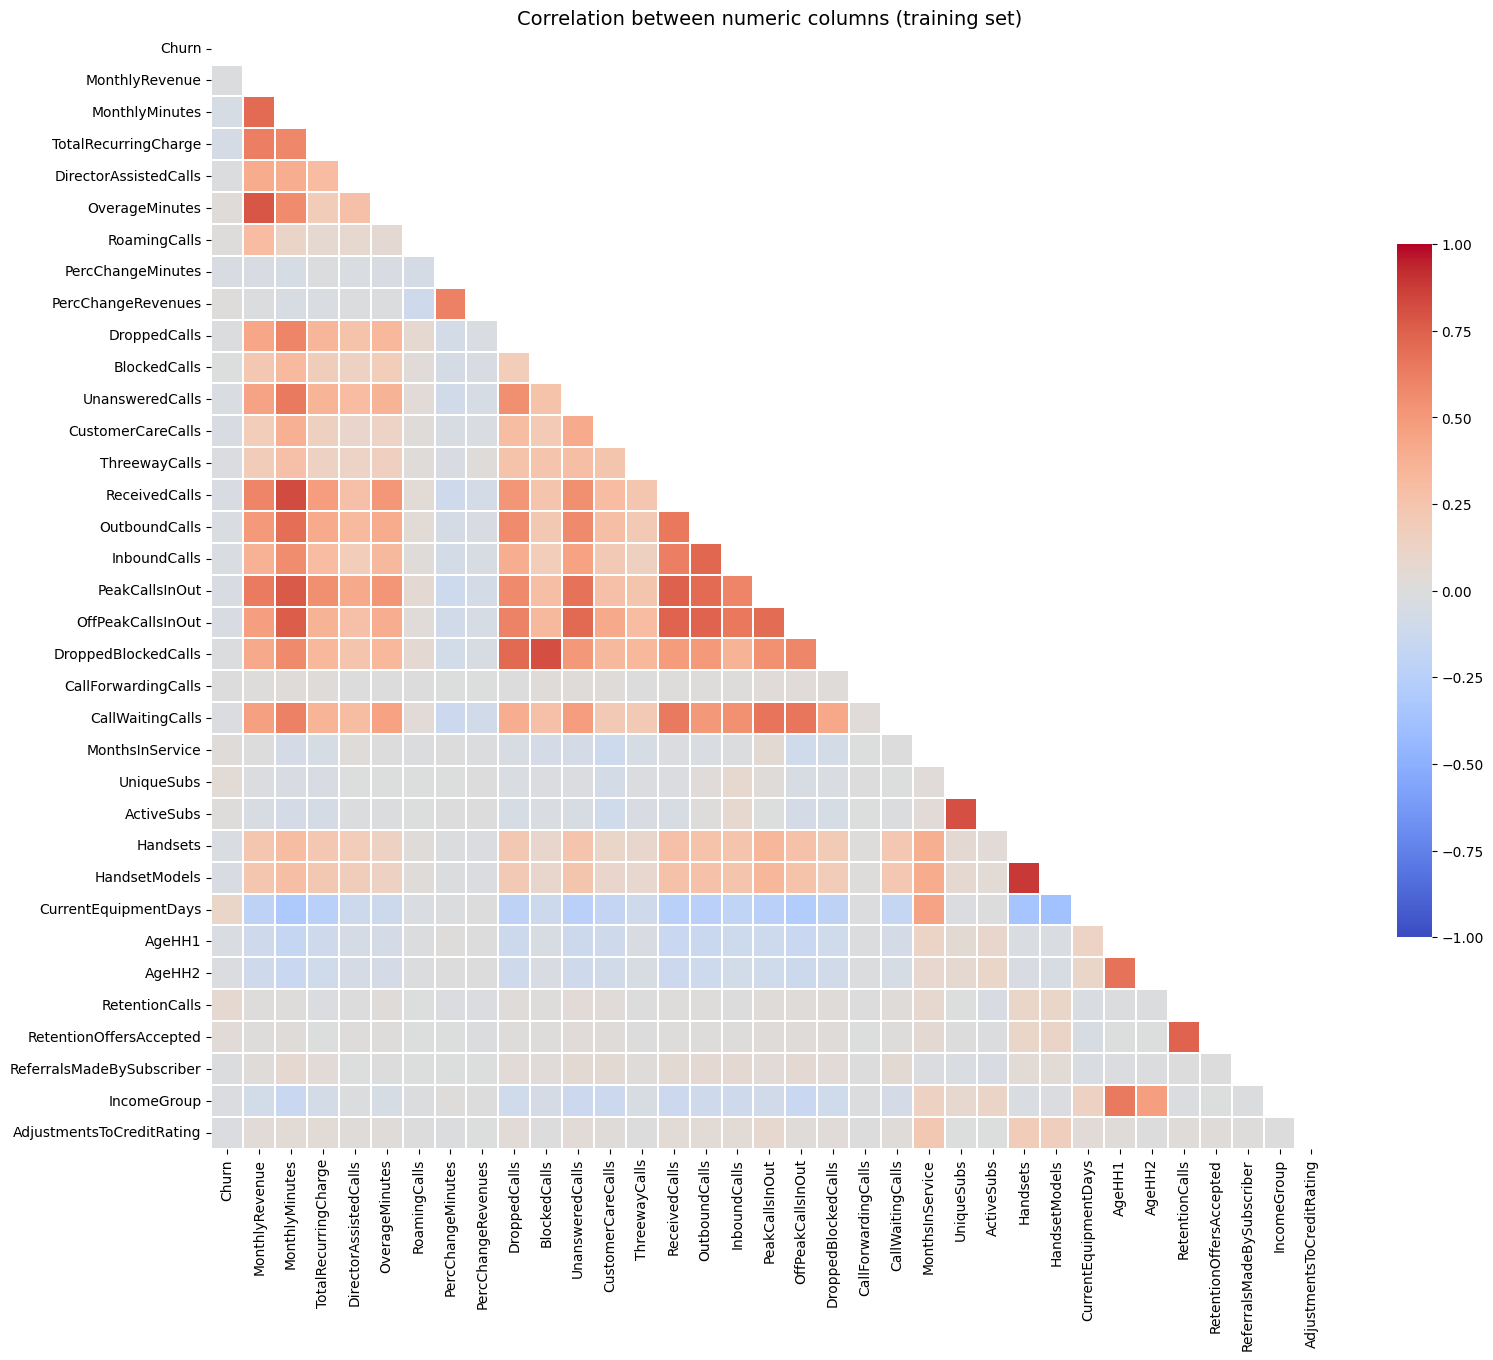

In [27]:
num = train_df.select_dtypes("number")
corr = num.corr()
mask = np.triu(np.ones_like(corr, dtype=bool))   # hide the duplicate upper half

plt.figure(figsize=(18, 15))
sns.heatmap(corr, mask=mask, cmap="coolwarm", center=0, vmin=-1, vmax=1,
            square=True, linewidths=0.3, cbar_kws={"shrink": 0.6})
plt.title("Correlation between numeric columns (training set)", fontsize=14)
plt.show()

### Which column pairs repeat each other?

In [28]:
lower = corr.where(np.tril(np.ones_like(corr, dtype=bool), k=-1)).stack()
lower = lower.reindex(lower.abs().sort_values(ascending=False).index)
print("Pairs with |correlation| > 0.7:")
print(lower[lower.abs() > 0.7].round(2).to_string())

Pairs with |correlation| > 0.7:
HandsetModels            Handsets           0.89
ReceivedCalls            MonthlyMinutes     0.83
DroppedBlockedCalls      BlockedCalls       0.82
ActiveSubs               UniqueSubs         0.81
OverageMinutes           MonthlyRevenue     0.78
PeakCallsInOut           MonthlyMinutes     0.77
OffPeakCallsInOut        MonthlyMinutes     0.76
PeakCallsInOut           ReceivedCalls      0.75
OffPeakCallsInOut        OutboundCalls      0.74
                         ReceivedCalls      0.74
RetentionOffersAccepted  RetentionCalls     0.73
InboundCalls             OutboundCalls      0.72
OffPeakCallsInOut        UnansweredCalls    0.72
DroppedBlockedCalls      DroppedCalls       0.72
MonthlyMinutes           MonthlyRevenue     0.71
PeakCallsInOut           OutboundCalls      0.71


### Correlation of each numeric column with churn

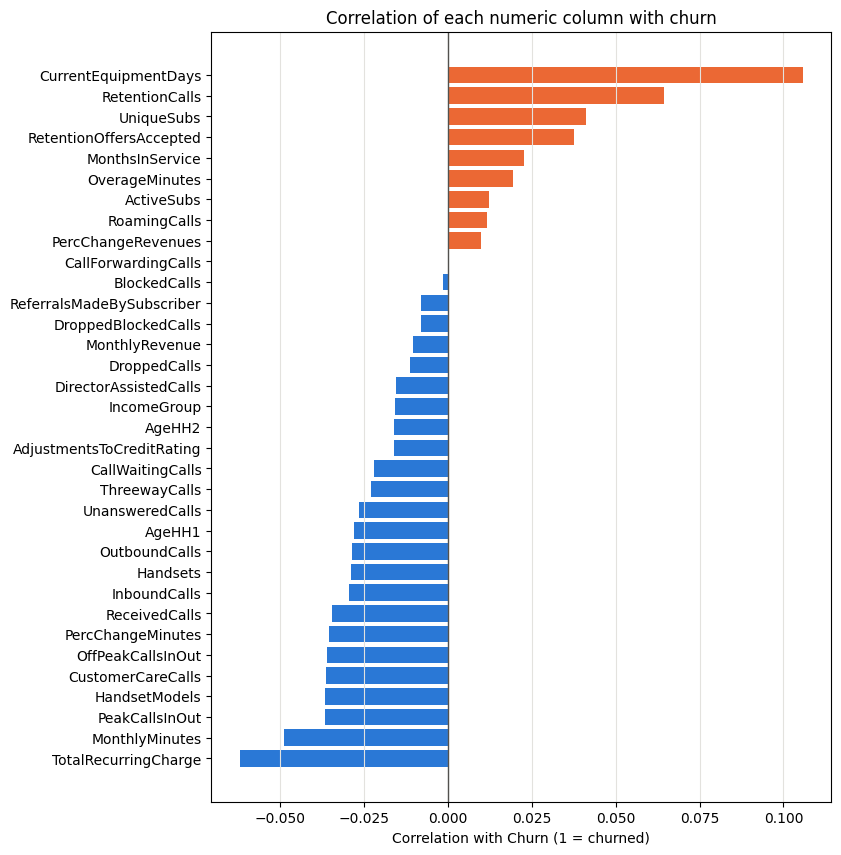

In [29]:
churn_corr = num.drop(columns="Churn").corrwith(train_df["Churn"]).sort_values()

fig, ax = plt.subplots(figsize=(8, 10))
ax.barh(churn_corr.index, churn_corr.values,
        color=[BLUE if v < 0 else ORANGE for v in churn_corr.values])
ax.axvline(0, color=GREY, linewidth=1)
ax.set_title("Correlation of each numeric column with churn")
ax.set_xlabel("Correlation with Churn (1 = churned)")
ax.grid(axis="x", color="#e3e2de")
ax.grid(axis="y", visible=False)
plt.show()

### Churn rate by categorical group

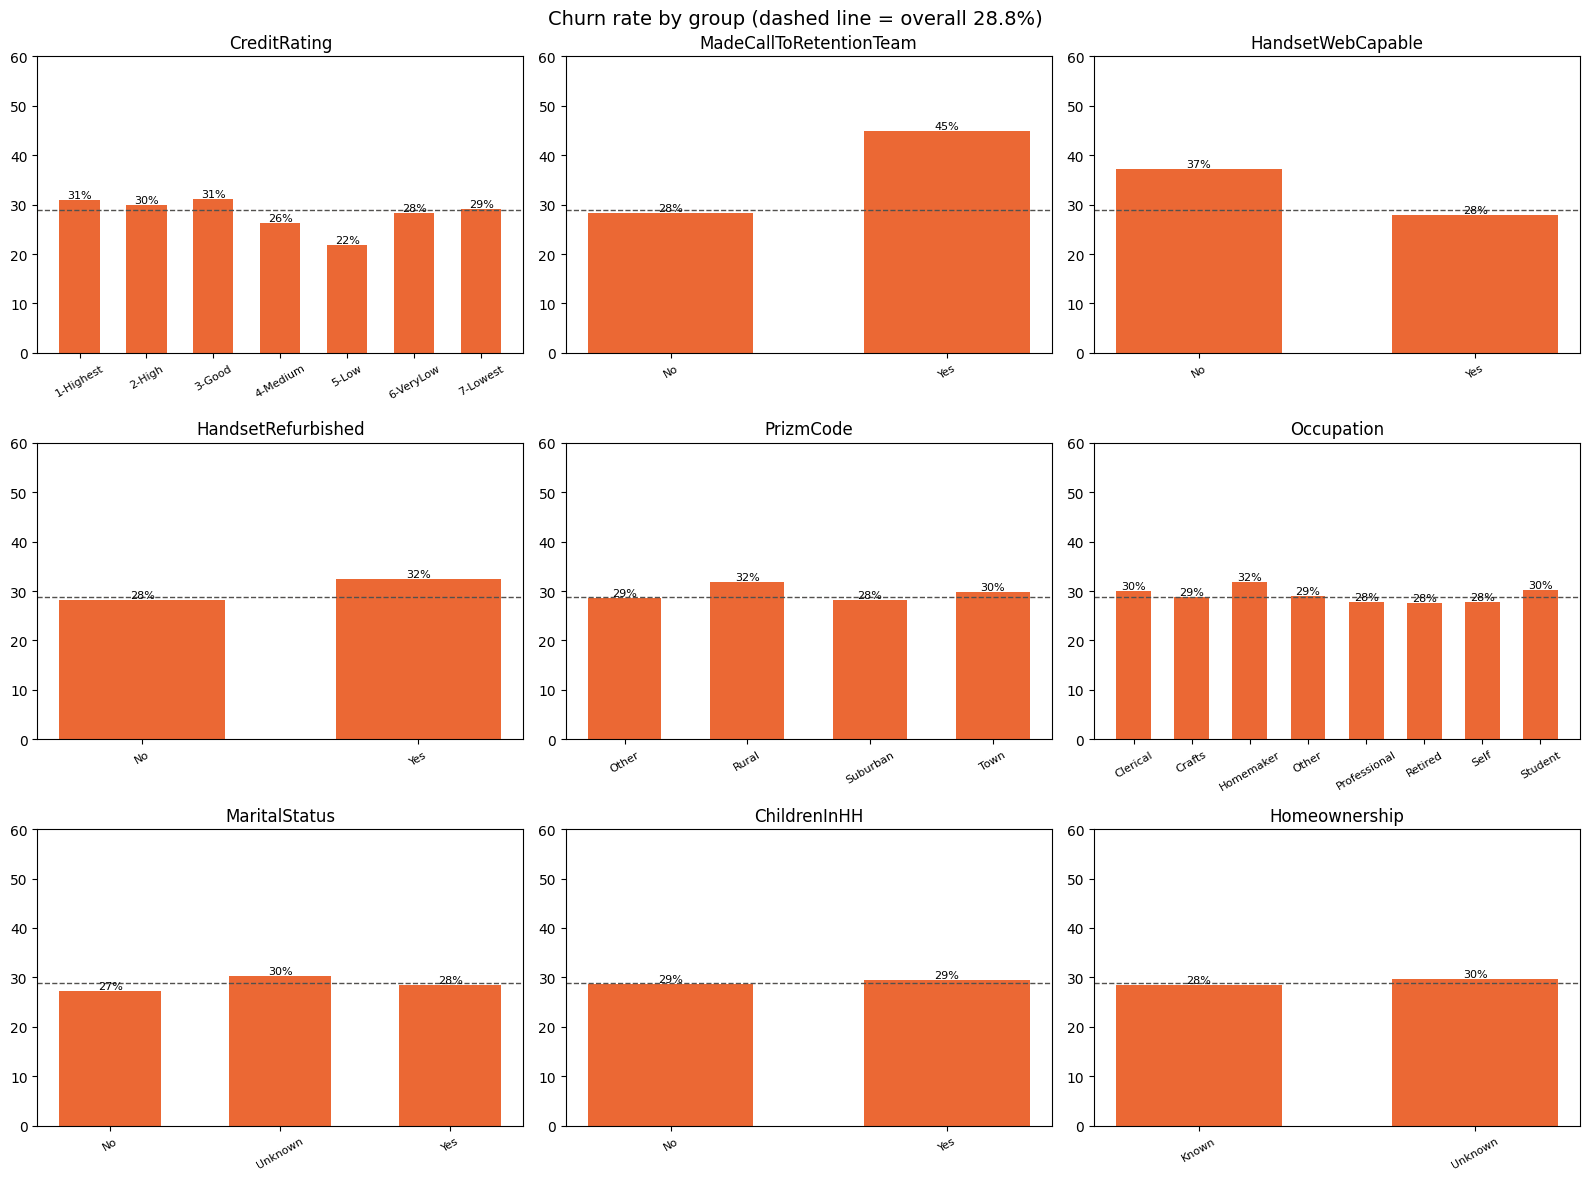

In [30]:
cat_cols = ["CreditRating", "MadeCallToRetentionTeam", "HandsetWebCapable", "HandsetRefurbished",
            "PrizmCode", "Occupation", "MaritalStatus", "ChildrenInHH", "Homeownership"]

fig, axes = plt.subplots(3, 3, figsize=(16, 12))
for ax, col in zip(axes.ravel(), cat_cols):
    rate = train_df.groupby(col)["Churn"].mean() * 100
    ax.bar(rate.index.astype(str), rate.values, color=ORANGE, width=0.6)
    ax.bar_label(ax.containers[0], fmt="%.0f%%", fontsize=8)
    ax.axhline(overall, color=GREY, linestyle="dashed", linewidth=1)
    ax.set_title(col)
    ax.set_ylim(0, 60)
    ax.tick_params(axis="x", rotation=30, labelsize=8)
plt.suptitle(f"Churn rate by group (dashed line = overall {overall:.1f}%)", fontsize=14)
plt.tight_layout()
plt.show()

### Churn rate across numeric ranges

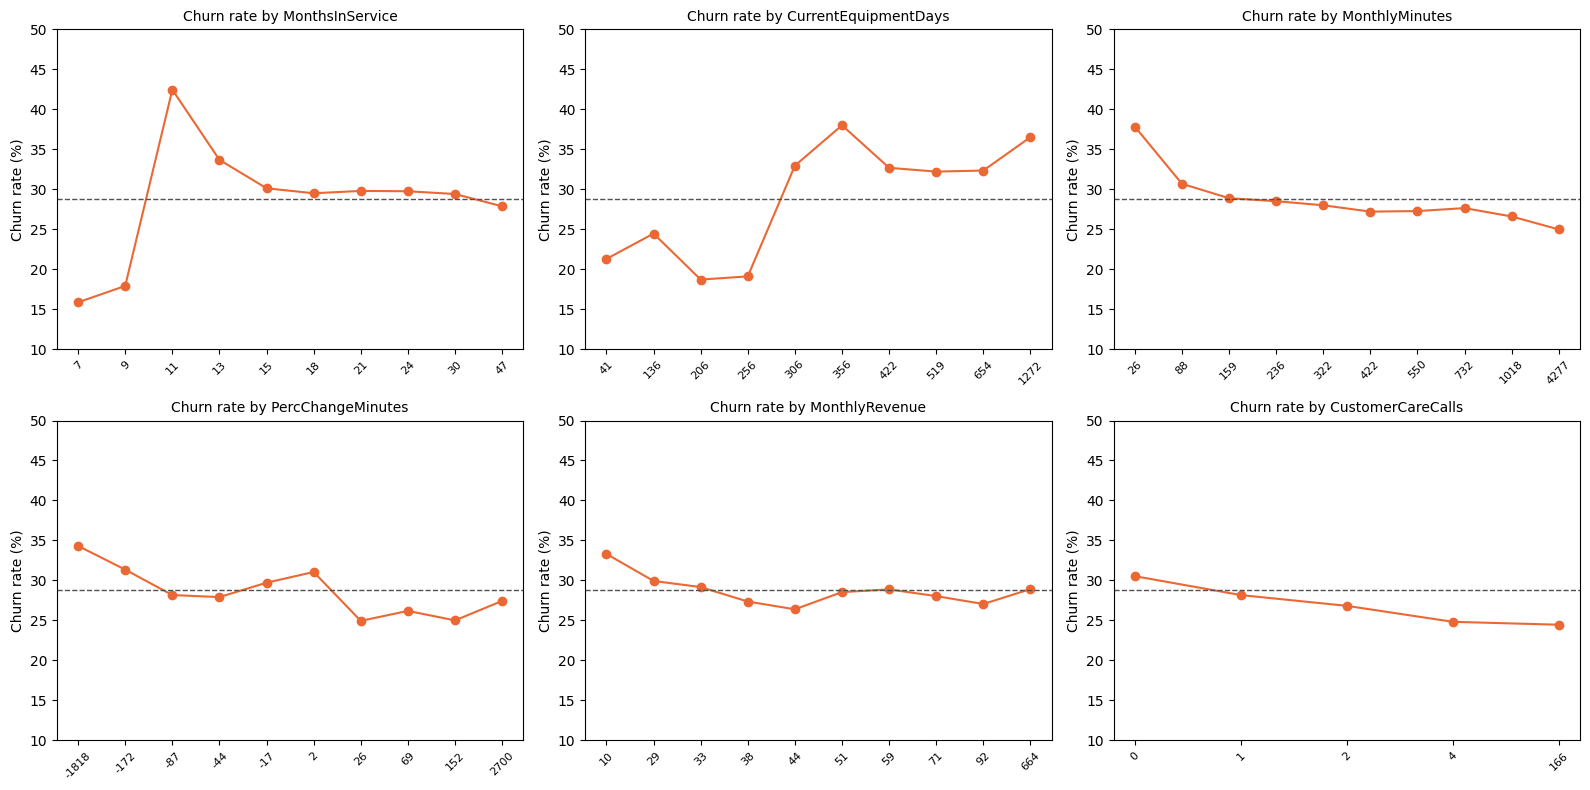

In [31]:
num_cols = ["MonthsInService", "CurrentEquipmentDays", "MonthlyMinutes",
            "PercChangeMinutes", "MonthlyRevenue", "CustomerCareCalls"]

fig, axes = plt.subplots(2, 3, figsize=(16, 8))
for ax, col in zip(axes.ravel(), num_cols):
    groups = pd.qcut(train_df[col], q=10, duplicates="drop")
    rate = train_df.groupby(groups, observed=True)["Churn"].mean() * 100
    ax.plot(range(len(rate)), rate.values, marker="o", color=ORANGE)
    ax.set_xticks(range(len(rate)))
    ax.set_xticklabels([f"{b.mid:.0f}" for b in rate.index], rotation=45, fontsize=8)
    ax.axhline(overall, color=GREY, linestyle="dashed", linewidth=1)
    ax.set_title(f"Churn rate by {col}", fontsize=10)
    ax.set_ylabel("Churn rate (%)")
    ax.set_ylim(10, 50)
plt.tight_layout()
plt.show()

### Skewed distributions: stayed vs. churned

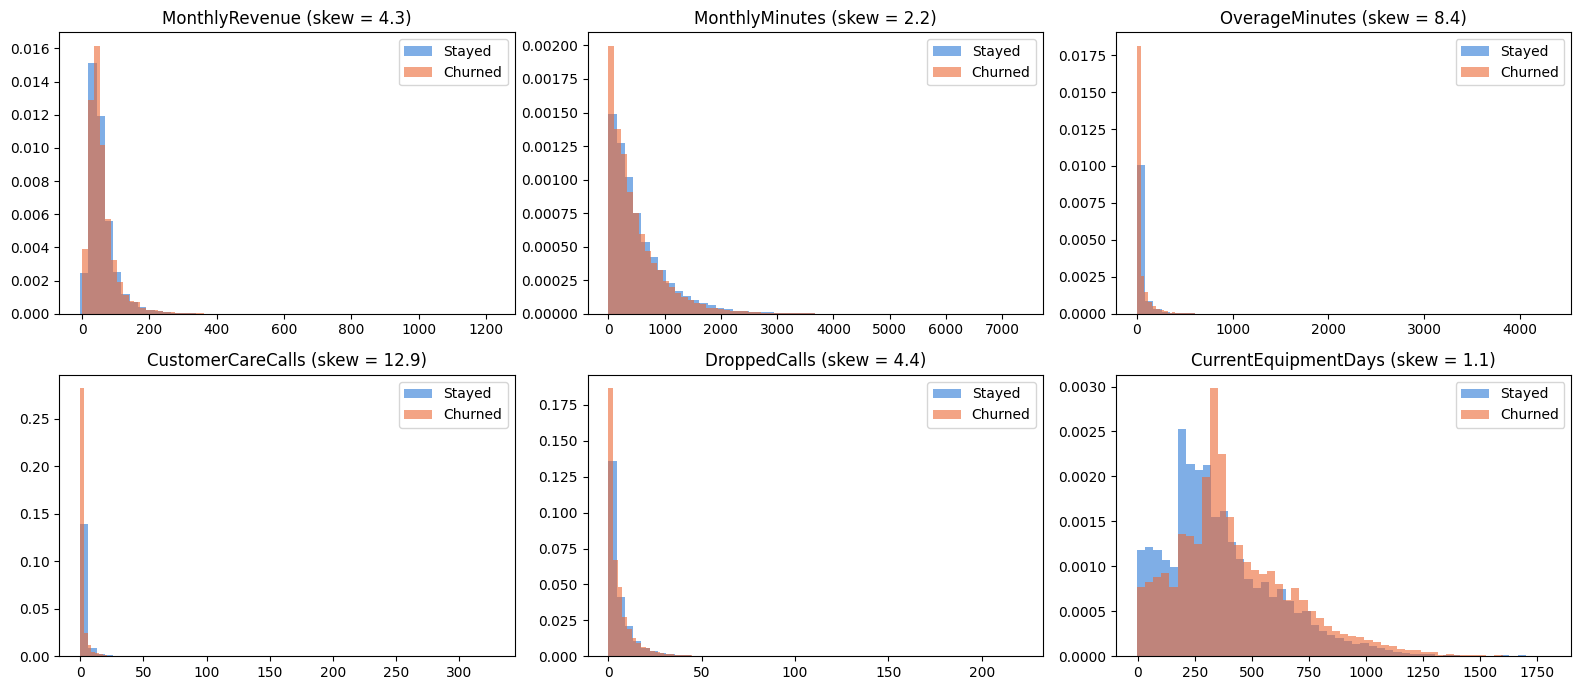

In [32]:
skew_cols = ["MonthlyRevenue", "MonthlyMinutes", "OverageMinutes",
             "CustomerCareCalls", "DroppedCalls", "CurrentEquipmentDays"]

fig, axes = plt.subplots(2, 3, figsize=(16, 7))
for ax, col in zip(axes.ravel(), skew_cols):
    for label, color, value in [("Stayed", BLUE, 0), ("Churned", ORANGE, 1)]:
        ax.hist(train_df.loc[train_df["Churn"] == value, col].dropna(), bins=50,
                alpha=0.6, color=color, label=label, density=True)
    ax.set_title(f"{col} (skew = {train_df[col].skew():.1f})")
    ax.legend()
plt.tight_layout()
plt.show()

---
# Part 3. Numbers used on the slides

The charts above only plot these values. Here they are printed so every slide number can be checked.

In [33]:
# Hidden "unknown" codes as a share of ALL 51,047 customers (the chart on the data-quality slide)
hidden = pd.Series({
    "HandsetPrice = Unknown":  (df["HandsetPrice"] == "Unknown").mean(),
    "AgeHH2 = 0":              (df["AgeHH2"] == 0).mean(),
    "MaritalStatus = Unknown": (df["MaritalStatus"] == "Unknown").mean(),
    "Homeownership = Unknown": (df["Homeownership"] == "Unknown").mean(),
    "AgeHH1 = 0":              (df["AgeHH1"] == 0).mean(),
    "IncomeGroup = 0":         (df["IncomeGroup"] == 0).mean(),
}) * 100
print("% of customers with a hidden 'unknown' code")
print(hidden.round(1).to_string())
print(f"\nLargest share of real blanks in any column (AgeHH1, AgeHH2): {df.isnull().mean().max() * 100:.1f}%")

% of customers with a hidden 'unknown' code
HandsetPrice = Unknown     56.8
AgeHH2 = 0                 51.1
MaritalStatus = Unknown    38.6
Homeownership = Unknown    33.4
AgeHH1 = 0                 27.3
IncomeGroup = 0            25.1

Largest share of real blanks in any column (AgeHH1, AgeHH2): 1.8%


In [34]:
# Churn rate and size of each customer group (training set). These feed the EDA slide and the business slide.
groups = {
    "Called retention team":                    train_df["MadeCallToRetentionTeam"] == "Yes",
    "Handset not web-capable":                  train_df["HandsetWebCapable"] == "No",
    "Near contract end (months 10-12, 22-24)":  train_df["MonthsInService"].isin([10, 11, 12, 22, 23, 24]),
    "Phone older than 1 year":                  train_df["CurrentEquipmentDays"] > 365,
    "First 12 months":                          train_df["MonthsInService"] <= 12,
    "Phone 1 year or newer":                    train_df["CurrentEquipmentDays"] <= 365,
    "Minutes fell more than 30%":               train_df["PercChangeMinutes"] < -30,
}
segments = pd.DataFrame({
    "Churn rate %":         {k: train_df.loc[m, "Churn"].mean() * 100 for k, m in groups.items()},
    "Share of customers %": {k: m.mean() * 100 for k, m in groups.items()},
}).round(1)
print(f"Overall churn rate in train: {overall:.1f}%")
segments

Overall churn rate in train: 28.8%


,Churn rate %,Share of customers %
Called retention team,44.9,3.4
Handset not web-capable,37.2,9.8
"Near contract end (months 10-12, 22-24)",34.5,25.5
Phone older than 1 year,33.5,43.3
First 12 months,26.4,33.3
Phone 1 year or newer,25.3,56.7
Minutes fell more than 30%,30.4,38.5


---
# Part 4. Cleaning and baseline models

### Basic cleaning

In [35]:
import warnings
warnings.filterwarnings("ignore")

def basic_clean(frame):
    frame = frame.copy()
    frame = frame.drop(columns="CustomerID", errors="ignore")
    frame["ServiceMarket"] = frame["ServiceArea"].str[:3]      # 747 areas -> 57 markets
    frame = frame.drop(columns="ServiceArea")
    frame["HandsetPrice"] = pd.to_numeric(frame["HandsetPrice"].replace("Unknown", np.nan))
    frame["CreditRating"] = frame["CreditRating"].str[0].astype(int)   # "1-Highest" -> 1
    frame["AgeHH1"] = frame["AgeHH1"].replace(0, np.nan)       # age 0 means unknown
    frame["IncomeGroup"] = frame["IncomeGroup"].replace(0, np.nan)
    return frame

train_clean = basic_clean(train_df)
test_clean = basic_clean(test_df)

X_train, y_train = train_clean.drop(columns="Churn"), train_clean["Churn"]
X_test, y_test = test_clean.drop(columns="Churn"), test_clean["Churn"]
print("X_train:", X_train.shape, " X_test:", X_test.shape)
print("Markets:", X_train["ServiceMarket"].nunique())

X_train: (40837, 56)  X_test: (10210, 56)
Markets: 57


> **What we changed:** `ServiceArea` cut to its first 3 characters (57 markets), `HandsetPrice` and `CreditRating` made numeric, and the 0 codes turned into missing values.

### Preprocessing pipeline

In [36]:
# Decision: all preprocessing lives inside a Pipeline, so each CV fold refits the imputer/scaler/encoder on its own training rows only (no leakage).
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder

num_cols = X_train.select_dtypes(include="number").columns.tolist()
cat_cols = X_train.select_dtypes(exclude="number").columns.tolist()

def make_preprocessor():
    return ColumnTransformer([
        ("num", Pipeline([
            ("impute", SimpleImputer(strategy="median", add_indicator=True)),  # adds a 0/1 "was missing" flag
            ("scale", StandardScaler())]), num_cols),
        ("cat", Pipeline([
            ("impute", SimpleImputer(strategy="most_frequent")),
            ("onehot", OneHotEncoder(handle_unknown="ignore", drop="if_binary"))]), cat_cols),  # one column per Yes/No
    ], sparse_threshold=0)

check = make_preprocessor().fit(X_train)
print("Numeric:", len(num_cols), " Categorical:", len(cat_cols))
print("Columns after preprocessing:", check.transform(X_train).shape[1])

Numeric: 36  Categorical: 20
Columns after preprocessing: 139


> **Pipeline:** median fill with “was missing” flags, scaling, and one-hot encoding with one column per Yes/No feature → **139 columns**.

### Baseline models (5-fold CV on train only)

In [37]:
# Baselines use default settings and the default 0.5 cutoff, scored with 5-fold stratified CV on the training set only.
import time
from sklearn.model_selection import StratifiedKFold, cross_validate
from sklearn.dummy import DummyClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier

models = {
    "Dummy": DummyClassifier(strategy="most_frequent"),
    "Logistic Regression": LogisticRegression(max_iter=3000),
    "Decision Tree": DecisionTreeClassifier(max_depth=5, random_state=42),
    "Random Forest": RandomForestClassifier(n_estimators=300, random_state=42, n_jobs=-1),
}

cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
scoring = {"accuracy": "accuracy", "precision": "precision", "recall": "recall",
           "f1": "f1", "roc_auc": "roc_auc", "pr_auc": "average_precision"}

rows = []
for name, model in models.items():
    start = time.time()
    pipe = Pipeline([("prep", make_preprocessor()), ("model", model)])
    res = cross_validate(pipe, X_train, y_train, cv=cv, scoring=scoring, n_jobs=-1)
    row = {"Model": name, **{m: res["test_" + m].mean() for m in scoring}}
    row["f1 std"] = res["test_f1"].std()
    rows.append(row)
    print(f"{name} done in {time.time() - start:.0f}s")

baseline_results = pd.DataFrame(rows).set_index("Model").round(3)
baseline_results

Dummy done in 7s
Logistic Regression done in 9s
Decision Tree done in 7s
Random Forest done in 158s


,accuracy,precision,recall,f1,roc_auc,pr_auc,f1 std
Model,,,,,,,
Dummy,0.712,0.000,0.000,0.000,0.500,0.288,0.000
Logistic Regression,0.713,0.520,0.047,0.086,0.619,0.386,0.009
Decision Tree,0.715,0.567,0.059,0.106,0.635,0.388,0.030
Random Forest,0.718,0.624,0.056,0.102,0.670,0.444,0.007


Compared Dummy, Logistic Regression, Decision Tree and Random Forest with 5-fold CV on the training set.

### Baseline results

> **Takeaway:** the baselines look accurate but catch almost no churners.

| | Result |
|---|---|
| **Accuracy** | about 71% for every model, no better than the Dummy |
| **Recall** | only about 5% |
| **Best at ranking customers** | Random Forest, ROC-AUC 0.670 |

The weak scores come from the **cutoff**, not the data. Churners are only 29% of customers, so a model’s churn probability rarely gets above 50%, and at the default 0.5 cutoff it predicts “stayed” for almost everyone.

---
# Part 5. Class weights and a tuned cutoff

In [38]:
from sklearn.model_selection import cross_val_predict
from sklearn.metrics import (roc_auc_score, average_precision_score, precision_recall_curve,
                             f1_score, precision_score, recall_score)

def oof_scores(model):
    # Out-of-fold churn probabilities on the training set (5-fold CV)
    pipe = Pipeline([("prep", make_preprocessor()), ("model", model)])
    proba = cross_val_predict(pipe, X_train, y_train, cv=cv, method="predict_proba", n_jobs=-1)[:, 1]
    pred = (proba >= 0.5).astype(int)

    # Cutoff that maximizes F1
    prec, rec, thr = precision_recall_curve(y_train, proba)
    f1 = 2 * prec * rec / (prec + rec + 1e-12)
    best = f1[:-1].argmax()

    return {"roc_auc": roc_auc_score(y_train, proba),
            "pr_auc": average_precision_score(y_train, proba),
            "precision @0.5": precision_score(y_train, pred, zero_division=0),
            "recall @0.5": recall_score(y_train, pred),
            "f1 @0.5": f1_score(y_train, pred),
            "best threshold": thr[best],
            "precision @best": prec[best],
            "recall @best": rec[best],
            "f1 @best": f1[best]}

balanced_models = {
    "Logistic Regression": LogisticRegression(max_iter=3000, class_weight="balanced"),
    "Decision Tree": DecisionTreeClassifier(max_depth=5, class_weight="balanced", random_state=42),
    "Random Forest": RandomForestClassifier(n_estimators=300, class_weight="balanced",
                                            random_state=42, n_jobs=-1),
}

rows = []
for name, model in balanced_models.items():
    start = time.time()
    rows.append({"Model": name, **oof_scores(model)})
    print(f"{name} done in {time.time() - start:.0f}s")

balanced_results = pd.DataFrame(rows).set_index("Model").round(3)
balanced_results

Logistic Regression done in 10s
Decision Tree done in 6s
Random Forest done in 155s


,roc_auc,pr_auc,precision @0.5,recall @0.5,f1 @0.5,best threshold,precision @best,recall @best,f1 @best
Model,,,,,,,,,
Logistic Regression,0.619,0.385,0.365,0.567,0.444,0.412,0.323,0.855,0.469
Decision Tree,0.634,0.395,0.355,0.711,0.474,0.422,0.341,0.844,0.485
Random Forest,0.669,0.439,0.644,0.048,0.089,0.257,0.366,0.777,0.498


### Result: class weights and a tuned cutoff

| | Result |
|---|---|
| **F1** | rises from about 0.09 to **0.47 to 0.50** |
| **Recall** | rises to roughly **0.8** |
| **Precision** | stays around 0.33 to 0.37 |
| **ROC-AUC** | unchanged |

> **Takeaway:** the models flag more churners, but they do not get better at ranking customers.

**Why Random Forest’s recall is still 0.048 at 0.5:** its fully grown trees end in tiny leaves that are all churn or all stay, so class weights barely move its probabilities. It only works with a lower cutoff (0.26), and there it is the best of the three, with F1 0.498.

---
# Part 6. XGBoost

In [39]:
# !pip install xgboost   # usually already installed in Colab
from xgboost import XGBClassifier

spw = (y_train == 0).sum() / (y_train == 1).sum()
print("scale_pos_weight:", round(spw, 2))

xgb = XGBClassifier(n_estimators=300, max_depth=4, learning_rate=0.05,
                    subsample=0.8, colsample_bytree=0.8, scale_pos_weight=spw,
                    eval_metric="logloss", random_state=42, n_jobs=-1)

start = time.time()
xgb_row = {"Model": "XGBoost", **oof_scores(xgb)}
print(f"XGBoost done in {time.time() - start:.0f}s")

all_results = pd.concat([balanced_results, pd.DataFrame([xgb_row]).set_index("Model").round(3)])
all_results

scale_pos_weight: 2.47
XGBoost done in 20s


,roc_auc,pr_auc,precision @0.5,recall @0.5,f1 @0.5,best threshold,precision @best,recall @best,f1 @best
Model,,,,,,,,,
Logistic Regression,0.619,0.385,0.365,0.567,0.444,0.412,0.323,0.855,0.469
Decision Tree,0.634,0.395,0.355,0.711,0.474,0.422,0.341,0.844,0.485
Random Forest,0.669,0.439,0.644,0.048,0.089,0.257,0.366,0.777,0.498
XGBoost,0.682,0.461,0.405,0.633,0.494,0.445,0.375,0.772,0.505


### Tune XGBoost

In [40]:
# Only XGBoost is tuned (10 random settings, scored on PR-AUC). Logistic Regression and Random Forest keep default settings.
from sklearn.model_selection import RandomizedSearchCV

search = RandomizedSearchCV(
    Pipeline([("prep", make_preprocessor()),
              ("model", XGBClassifier(scale_pos_weight=spw, eval_metric="logloss",
                                      random_state=42, n_jobs=-1))]),
    param_distributions={
        "model__n_estimators": [200, 400, 600],
        "model__max_depth": [3, 4, 5, 6],
        "model__learning_rate": [0.02, 0.05, 0.1],
        "model__subsample": [0.7, 0.85, 1.0],
        "model__colsample_bytree": [0.5, 0.7, 0.9],
        "model__min_child_weight": [1, 5, 10],
    },
    n_iter=10, scoring="average_precision", cv=cv, random_state=42, n_jobs=1)

start = time.time()
search.fit(X_train, y_train)
print(f"Search done in {time.time() - start:.0f}s")
print("Best CV PR-AUC:", round(search.best_score_, 3))
print("Best settings:", {k.replace("model__", ""): v for k, v in search.best_params_.items()})

best_xgb = search.best_estimator_.named_steps["model"]
tuned_row = {"Model": "XGBoost (tuned)", **oof_scores(best_xgb)}
all_results = pd.concat([all_results, pd.DataFrame([tuned_row]).set_index("Model").round(3)])
all_results

Search done in 293s
Best CV PR-AUC: 0.465
Best settings: {'subsample': 1.0, 'n_estimators': 600, 'min_child_weight': 10, 'max_depth': 4, 'learning_rate': 0.05, 'colsample_bytree': 0.7}


,roc_auc,pr_auc,precision @0.5,recall @0.5,f1 @0.5,best threshold,precision @best,recall @best,f1 @best
Model,,,,,,,,,
Logistic Regression,0.619,0.385,0.365,0.567,0.444,0.412,0.323,0.855,0.469
Decision Tree,0.634,0.395,0.355,0.711,0.474,0.422,0.341,0.844,0.485
Random Forest,0.669,0.439,0.644,0.048,0.089,0.257,0.366,0.777,0.498
XGBoost,0.682,0.461,0.405,0.633,0.494,0.445,0.375,0.772,0.505
XGBoost (tuned),0.682,0.464,0.412,0.614,0.493,0.421,0.369,0.789,0.503


### Result: XGBoost

| | ROC-AUC | PR-AUC |
|---|---|---|
| **XGBoost, default settings** | 0.682 | 0.461 |
| **XGBoost, tuned (10 random settings)** | 0.682 | 0.464 |

> **Takeaway:** XGBoost is the best model so far and beats Random Forest without any tuning. Tuning added almost nothing, so the default settings were already about as good as tuning gets.

---
# Part 7. Feature engineering: 13 new columns

In [41]:
def add_features(frame):
    f = frame.copy()
    minutes = f["MonthlyMinutes"]
    # Phone age (the strongest numeric signal in the EDA)
    f["EquipmentAgeMonths"] = f["CurrentEquipmentDays"] / 30.4
    f["EquipmentOverYear"] = (f["CurrentEquipmentDays"] > 365).astype(int)
    f["EquipmentToTenure"] = f["EquipmentAgeMonths"] / f["MonthsInService"]
    # The churn spike around 11 months, likely contracts ending
    f["NearContractEnd"] = f["MonthsInService"].isin([10, 11, 12, 22, 23, 24]).astype(int)
    # Service quality and usage, relative to how much they use the phone
    f["DroppedPerMinute"] = f["DroppedBlockedCalls"] / (minutes + 1)
    f["CareCallsPerMinute"] = f["CustomerCareCalls"] / (minutes + 1)
    f["OverageShare"] = f["OverageMinutes"] / (minutes + 1)
    f["RevenuePerMinute"] = f["MonthlyRevenue"] / (minutes + 1)
    f["RecurringShare"] = f["TotalRecurringCharge"] / f["MonthlyRevenue"].where(f["MonthlyRevenue"] > 0)
    # Behavior flags
    f["MinutesDropped30"] = (f["PercChangeMinutes"] < -30).astype(int)
    f["LowUse"] = (minutes < 100).astype(int)
    f["ActiveShare"] = f["ActiveSubs"] / f["UniqueSubs"]
    f["ContactedRetention"] = (f["RetentionCalls"] > 0).astype(int)
    return f

X_train_fe = add_features(X_train)
X_test_fe = add_features(X_test)

# The preprocessor reads these lists, so update them to include the new columns
num_cols = X_train_fe.select_dtypes(include="number").columns.tolist()
cat_cols = X_train_fe.select_dtypes(exclude="number").columns.tolist()
print("Features before:", X_train.shape[1], " after:", X_train_fe.shape[1])

Features before: 56  after: 69


### Compare with and without the new features (LR and XGBoost)

In [42]:
def quick_scores(model, X_part):
    pipe = Pipeline([("prep", make_preprocessor()), ("model", model)])
    proba = cross_val_predict(pipe, X_part, y_train, cv=cv, method="predict_proba", n_jobs=-1)[:, 1]
    return {"roc_auc": roc_auc_score(y_train, proba),
            "pr_auc": average_precision_score(y_train, proba)}

lr_bal = LogisticRegression(max_iter=3000, class_weight="balanced")
rows = []
for feats, X_part in [("original", X_train), ("+ new features", X_train_fe)]:
    num_cols = X_part.select_dtypes(include="number").columns.tolist()
    cat_cols = X_part.select_dtypes(exclude="number").columns.tolist()
    for name, model in [("Logistic Regression", lr_bal), ("XGBoost (tuned)", best_xgb)]:
        rows.append({"Model": name, "Features": feats, **quick_scores(model, X_part)})

fe_results = pd.DataFrame(rows).set_index(["Model", "Features"]).round(3)
fe_results

,,roc_auc,pr_auc
Model,Features,,
Logistic Regression,original,0.619,0.385
XGBoost (tuned),original,0.682,0.464
Logistic Regression,+ new features,0.638,0.403
XGBoost (tuned),+ new features,0.685,0.468


We built 13 features from the EDA patterns: phone age, the contract-end window, service quality per minute, money per minute, and usage-drop flags.

### Result: with and without the new features

| Model | ROC-AUC before | ROC-AUC after |
|---|---|---|
| **Logistic Regression** | 0.619 | **0.638** |
| **XGBoost (tuned)** | 0.682 | **0.685** |

> **Takeaway:** the new features help Logistic Regression, but XGBoost barely moves because its trees were already finding these patterns. Our final model is **XGBoost (tuned) with the new features**, the best in every CV table.

---
# Part 8. Balancing and feature selection

### Balancing: none, class weights, SMOTE

In [43]:
from sklearn.base import clone
from imblearn.pipeline import Pipeline as ImbPipeline
from imblearn.over_sampling import SMOTE

num_cols = X_train_fe.select_dtypes(include="number").columns.tolist()
cat_cols = X_train_fe.select_dtypes(exclude="number").columns.tolist()

def score_pipe(pipe):
    proba = cross_val_predict(pipe, X_train_fe, y_train, cv=cv, method="predict_proba", n_jobs=-1)[:, 1]
    prec, rec, thr = precision_recall_curve(y_train, proba)
    f1 = 2 * prec * rec / (prec + rec + 1e-12)
    b = f1[:-1].argmax()
    return {"roc_auc": roc_auc_score(y_train, proba), "pr_auc": average_precision_score(y_train, proba),
            "f1 @best": f1[b], "recall @best": rec[b], "precision @best": prec[b]}

options = {
    "Logistic Regression": {"none": clone(lr_bal).set_params(class_weight=None),
                            "class weights": clone(lr_bal),
                            "SMOTE": clone(lr_bal).set_params(class_weight=None)},
    "XGBoost": {"none": clone(best_xgb).set_params(scale_pos_weight=1),
                "class weights": clone(best_xgb),
                "SMOTE": clone(best_xgb).set_params(scale_pos_weight=1)},
}

rows = []
for model_name, choices in options.items():
    for balance, model in choices.items():
        steps = [("prep", make_preprocessor())]
        if balance == "SMOTE":
            steps.append(("smote", SMOTE(random_state=42)))   # only resamples the training folds
        steps.append(("model", model))
        rows.append({"Model": model_name, "Balancing": balance, **score_pipe(ImbPipeline(steps))})

balance_results = pd.DataFrame(rows).set_index(["Model", "Balancing"]).round(3)
balance_results

roc_auc  pr_auc  f1 @best  recall @best  \
Model               Balancing                                                
Logistic Regression none             0.638   0.403     0.480         0.818   
                    class weights    0.638   0.403     0.480         0.780   
                    SMOTE            0.633   0.399     0.476         0.765   
XGBoost             none             0.686   0.469     0.507         0.755   
                    class weights    0.685   0.468     0.506         0.791   
                    SMOTE            0.681   0.460     0.503         0.724   

                                   precision @best  
Model               Balancing                       
Logistic Regression none                     0.340  
                    class weights            0.346  
                    SMOTE                    0.345  
XGBoost             none                     0.382  
                    class weights            0.372  
                    SMOTE                    0.385

### Feature selection with ANOVA (SelectKBest, top k columns)

In [44]:
from sklearn.feature_selection import SelectKBest, f_classif

n_total = make_preprocessor().fit(X_train_fe).transform(X_train_fe.head()).shape[1]
print("Total encoded columns:", n_total)

rows = []
for model_name, model in [("Logistic Regression", lr_bal), ("XGBoost", best_xgb)]:
    for k in [20, 40, 60, 80, 100, "all"]:
        pipe = Pipeline([("prep", make_preprocessor()),
                         ("select", SelectKBest(f_classif, k=k)),   # refit inside every fold
                         ("model", clone(model))])
        rows.append({"Model": model_name, "k": k, **score_pipe(pipe)})

selection_results = pd.DataFrame(rows).set_index(["Model", "k"]).round(3)
selection_results

Total encoded columns: 159


roc_auc  pr_auc  f1 @best  recall @best  \
Model               k                                              
Logistic Regression 20     0.620   0.385     0.473         0.840   
                    40     0.632   0.395     0.478         0.778   
                    60     0.635   0.397     0.480         0.786   
                    80     0.638   0.401     0.481         0.775   
                    100    0.639   0.403     0.481         0.818   
                    all    0.638   0.403     0.480         0.780   
XGBoost             20     0.653   0.429     0.487         0.833   
                    40     0.677   0.460     0.500         0.774   
                    60     0.681   0.463     0.504         0.712   
                    80     0.682   0.465     0.503         0.781   
                    100    0.685   0.467     0.504         0.763   
                    all    0.685   0.468     0.506         0.791   

                         precision @best  
Model               k                     
Logistic Regression 20             0.329  
                    40             0.345  
                    60             0.346  
                    80             0.348  
                    100            0.340  
                    all            0.346  
XGBoost             20             0.345  
                    40             0.369  
                    60             0.390  
                    80             0.371  
                    100            0.377  
                    all            0.372

### Result: balancing and feature selection

**Balancing**

- None, class weights and SMOTE score almost the same (XGBoost ROC-AUC 0.681 to 0.686).
- Once the cutoff is tuned, the balancing method barely matters. SMOTE is slightly worse and slower, just like on Telco.

**Feature selection**

- XGBoost holds steady from 60 to all 159 columns (PR-AUC 0.463 to 0.468) and only drops at 20 columns (0.429).
- Logistic Regression is flat from 80 columns up.

> **Takeaway:** we can cut about half the columns for free, but nothing improves, so we keep them all.

> **Final model:** XGBoost with tuned settings, all 159 columns and class weights. It is tied for best on every metric and is the simplest option.

---
# Part 9. Final model and test result

### Lock in the final model and pick the cutoff

In [45]:
# Make sure the column lists match the feature-engineered data
num_cols = X_train_fe.select_dtypes(include="number").columns.tolist()
cat_cols = X_train_fe.select_dtypes(exclude="number").columns.tolist()

final_pipe = Pipeline([("prep", make_preprocessor()), ("model", best_xgb)])

# Choose the cutoff from out-of-fold predictions on TRAIN
oof = cross_val_predict(final_pipe, X_train_fe, y_train, cv=cv, method="predict_proba", n_jobs=-1)[:, 1]
prec, rec, thr = precision_recall_curve(y_train, oof)
f1 = 2 * prec * rec / (prec + rec + 1e-12)
threshold = thr[f1[:-1].argmax()]
print("Chosen threshold (from CV):", round(float(threshold), 3))
print("CV ROC-AUC:", round(roc_auc_score(y_train, oof), 3))

Chosen threshold (from CV): 0.421
CV ROC-AUC: 0.685


### Score the test set once

Test ROC-AUC:         0.684
Test PR-AUC:          0.464
              precision    recall  f1-score   support

      Stayed       0.84      0.44      0.58      7268
     Churned       0.37      0.80      0.50      2942

    accuracy                           0.54     10210
   macro avg       0.60      0.62      0.54     10210
weighted avg       0.71      0.54      0.56     10210



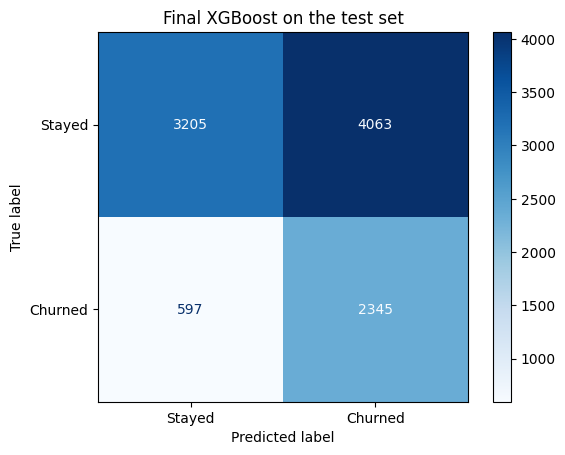

In [46]:
# The test set is scored ONCE, with the cutoff chosen from training-set cross-validation (previous cell).
from sklearn.metrics import classification_report, ConfusionMatrixDisplay

final_pipe.fit(X_train_fe, y_train)
test_proba = final_pipe.predict_proba(X_test_fe)[:, 1]
test_pred = (test_proba >= threshold).astype(int)

print(f"Test ROC-AUC:         {roc_auc_score(y_test, test_proba):.3f}")
print(f"Test PR-AUC:          {average_precision_score(y_test, test_proba):.3f}")
print(classification_report(y_test, test_pred, target_names=["Stayed", "Churned"]))

ConfusionMatrixDisplay.from_predictions(y_test, test_pred, display_labels=["Stayed", "Churned"], cmap="Blues")
plt.title("Final XGBoost on the test set")
plt.grid(False)
plt.show()

### Which features matter most

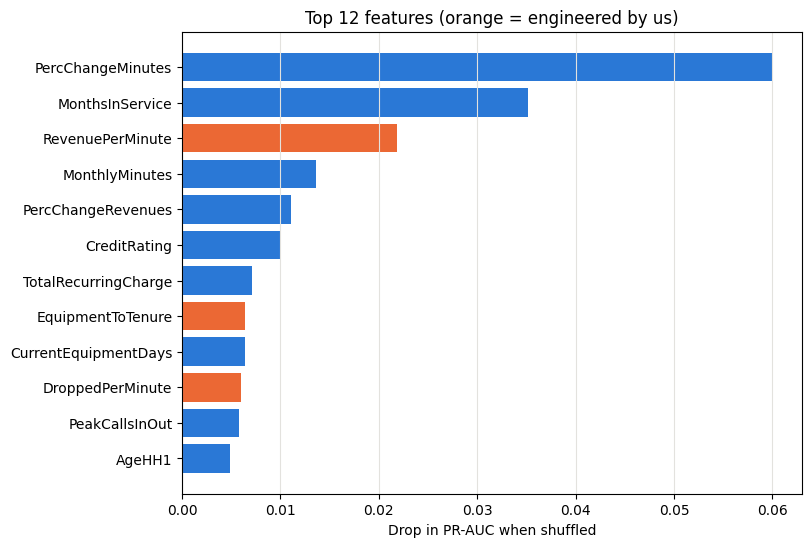

,0
PercChangeMinutes,0.0600
MonthsInService,0.0351
RevenuePerMinute,0.0219
MonthlyMinutes,0.0136
PercChangeRevenues,0.0111
CreditRating,0.0100
TotalRecurringCharge,0.0071
EquipmentToTenure,0.0064
CurrentEquipmentDays,0.0064
DroppedPerMinute,0.0060


In [47]:
from sklearn.inspection import permutation_importance

r = permutation_importance(final_pipe, X_test_fe, y_test, scoring="average_precision",
                           n_repeats=5, random_state=42, n_jobs=-1)
importance = pd.Series(r.importances_mean, index=X_test_fe.columns).sort_values(ascending=False)

top = importance.head(12).sort_values()
fig, ax = plt.subplots(figsize=(8, 6))
ax.barh(top.index, top.values, color=[ORANGE if c in add_features(X_train.head()).columns.difference(X_train.columns) else BLUE for c in top.index])
ax.set_xlabel("Drop in PR-AUC when shuffled")
ax.set_title("Top 12 features (orange = engineered by us)")
ax.grid(axis="x", color="#e3e2de")
ax.grid(axis="y", visible=False)
plt.show()
importance.head(12).round(4)

### Final result on the test set

| | Result |
|---|---|
| **Cutoff** | 0.421, chosen from training-set cross-validation (below the default 0.5 because churners are the minority) |
| **ROC-AUC** | 0.684 (CV 0.685) |
| **PR-AUC** | 0.464 (random guessing = 0.288) |
| **Recall** | 0.80: caught 2,345 of 2,942 churners |
| **Precision** | 0.37: of 6,408 customers flagged, 37% actually churned |

Test scores match cross-validation, so the model is not overfitting.

### What drives churn

1. **Drop in minutes used** is the strongest signal.
2. **Months in service** comes next.
3. **Revenue per minute**, one of our engineered features, is third.

Three of the top 12 features are ones we built.